# Forecast Using Kumo

In [ ]:
!UV_CONSTRAINT= UV_BUILD_CONSTRAINT= uv pip install -q "foundationforecast[plot]"

foundationforecast ships a `Kumo` class for [NVIDIA](https://huggingface.co/nvidia)'s [Kumo-Forecast](https://huggingface.co/nvidia/Kumo-Forecast) model ([Kumo-TS](https://github.com/NVIDIA/Kumo-TS)):

| Checkpoint | `checkpoint` | Cross-channel attention | Parameters | Context | Native horizon |
|------------|--------------|-------------------------|------------|---------|----------------|
| **Kumo-Forecast** (default) | `run8_best_model_cr.pt` | Yes | ~340M | 512 | 72 |
| **Kumo-Forecast base** | `moment_head_512_6hr.pt` | No | ~340M | 512 | 72 |

Both live in the `nvidia/Kumo-Forecast` repo; pick one with `Kumo(checkpoint=...)`. Each series is forecast on its own, so cross-channel attention has a single channel to mix here; the notebook compares the two checkpoints on that setup.

Kumo-Forecast is a MOMENT-style T5 encoder with a linear forecasting head. A few things to know:

- Series shorter than 512 observations are left-padded and masked; longer series are truncated to their last 512 values. Missing values are masked too.
- Horizons beyond 72 steps are produced by feeding the forecast back as context (autoregressive rollout).
- **It produces point forecasts only.** There is no native quantile head, so `level` and `quantiles` need conformal intervals (see below).

The model runs through the [`timecopilot-kumo-forecast`](https://github.com/TimeCopilot/timecopilot-kumo-forecast) package, an inference-only packaging of the upstream code.

## Import libraries

In [2]:
import pandas as pd

from foundationforecast import ConformalIntervals, FoundationForecast

## Load the dataset

The DataFrame must include at least the following columns:
- unique_id: Unique identifier for each time series (string)
- ds: Date column (datetime format)
- y: Target variable for forecasting (float format)

The pandas frequency will be inferred from the ds column, if not provided.
If the seasonality is not provided, it will be inferred based on the frequency.
If the horizon is not set, it will default to 2 times the inferred seasonality.

In [3]:
df = pd.read_parquet(
    "https://timecopilot.s3.amazonaws.com/public/data/m4-hourly.parquet"
)
df = df[df["unique_id"].isin(df["unique_id"].unique()[:8])]
df.head()

,unique_id,ds,y
0,H1,2000-01-01 00:00:00,605.0
1,H1,2000-01-01 01:00:00,586.0
2,H1,2000-01-01 02:00:00,586.0
3,H1,2000-01-01 03:00:00,559.0
4,H1,2000-01-01 04:00:00,511.0


## Plot the data

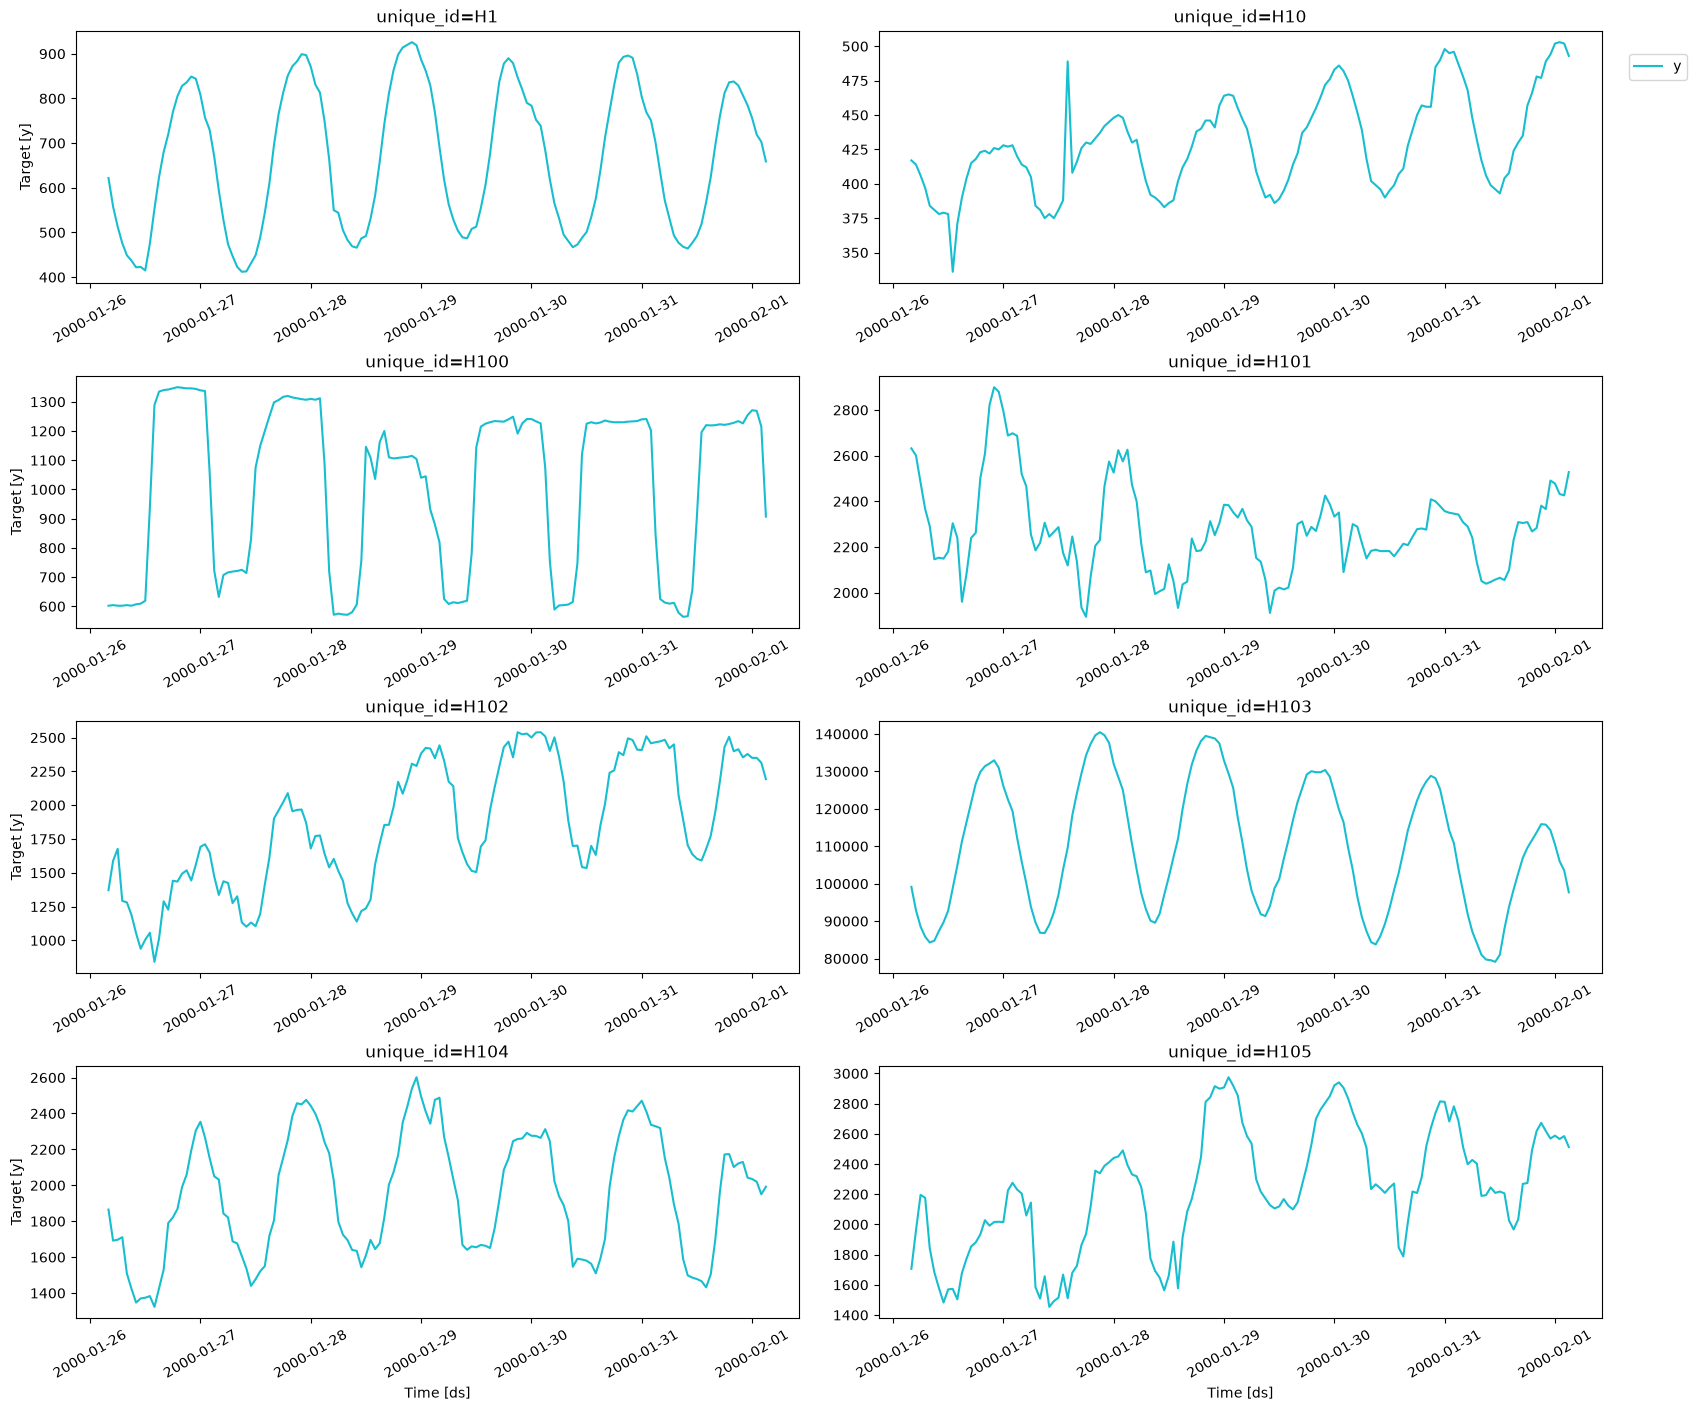

In [4]:
FoundationForecast.plot(df, max_insample_length=48 * 3, plot_random=False)

## Import the models

In [5]:
from foundationforecast.models import Kumo

## Create a FoundationForecast

In [6]:
models = [
    Kumo(alias="Kumo"),
    Kumo(checkpoint="moment_head_512_6hr.pt", alias="Kumo-base"),
]

ff = FoundationForecast(models=models)

## Generate forecast

You can optionally specify the following parameters:
- freq: The frequency of your data (e.g., 'D' for daily, 'M' for monthly)
- h: The forecast horizon, which is the number of periods to predict
- seasonality: The seasonal period of your data, which can be inferred if not provided

In [7]:
h = 48
fcst_df = ff.forecast(df=df, h=h)
fcst_df.head()

,unique_id,ds,Kumo,Kumo-base
0,H1,2000-02-01 04:00:00,619.416809,758.959656
1,H1,2000-02-01 05:00:00,579.589050,816.005615
2,H1,2000-02-01 06:00:00,532.249451,774.137329
3,H1,2000-02-01 07:00:00,500.108124,750.082458
4,H1,2000-02-01 08:00:00,483.022736,833.545044


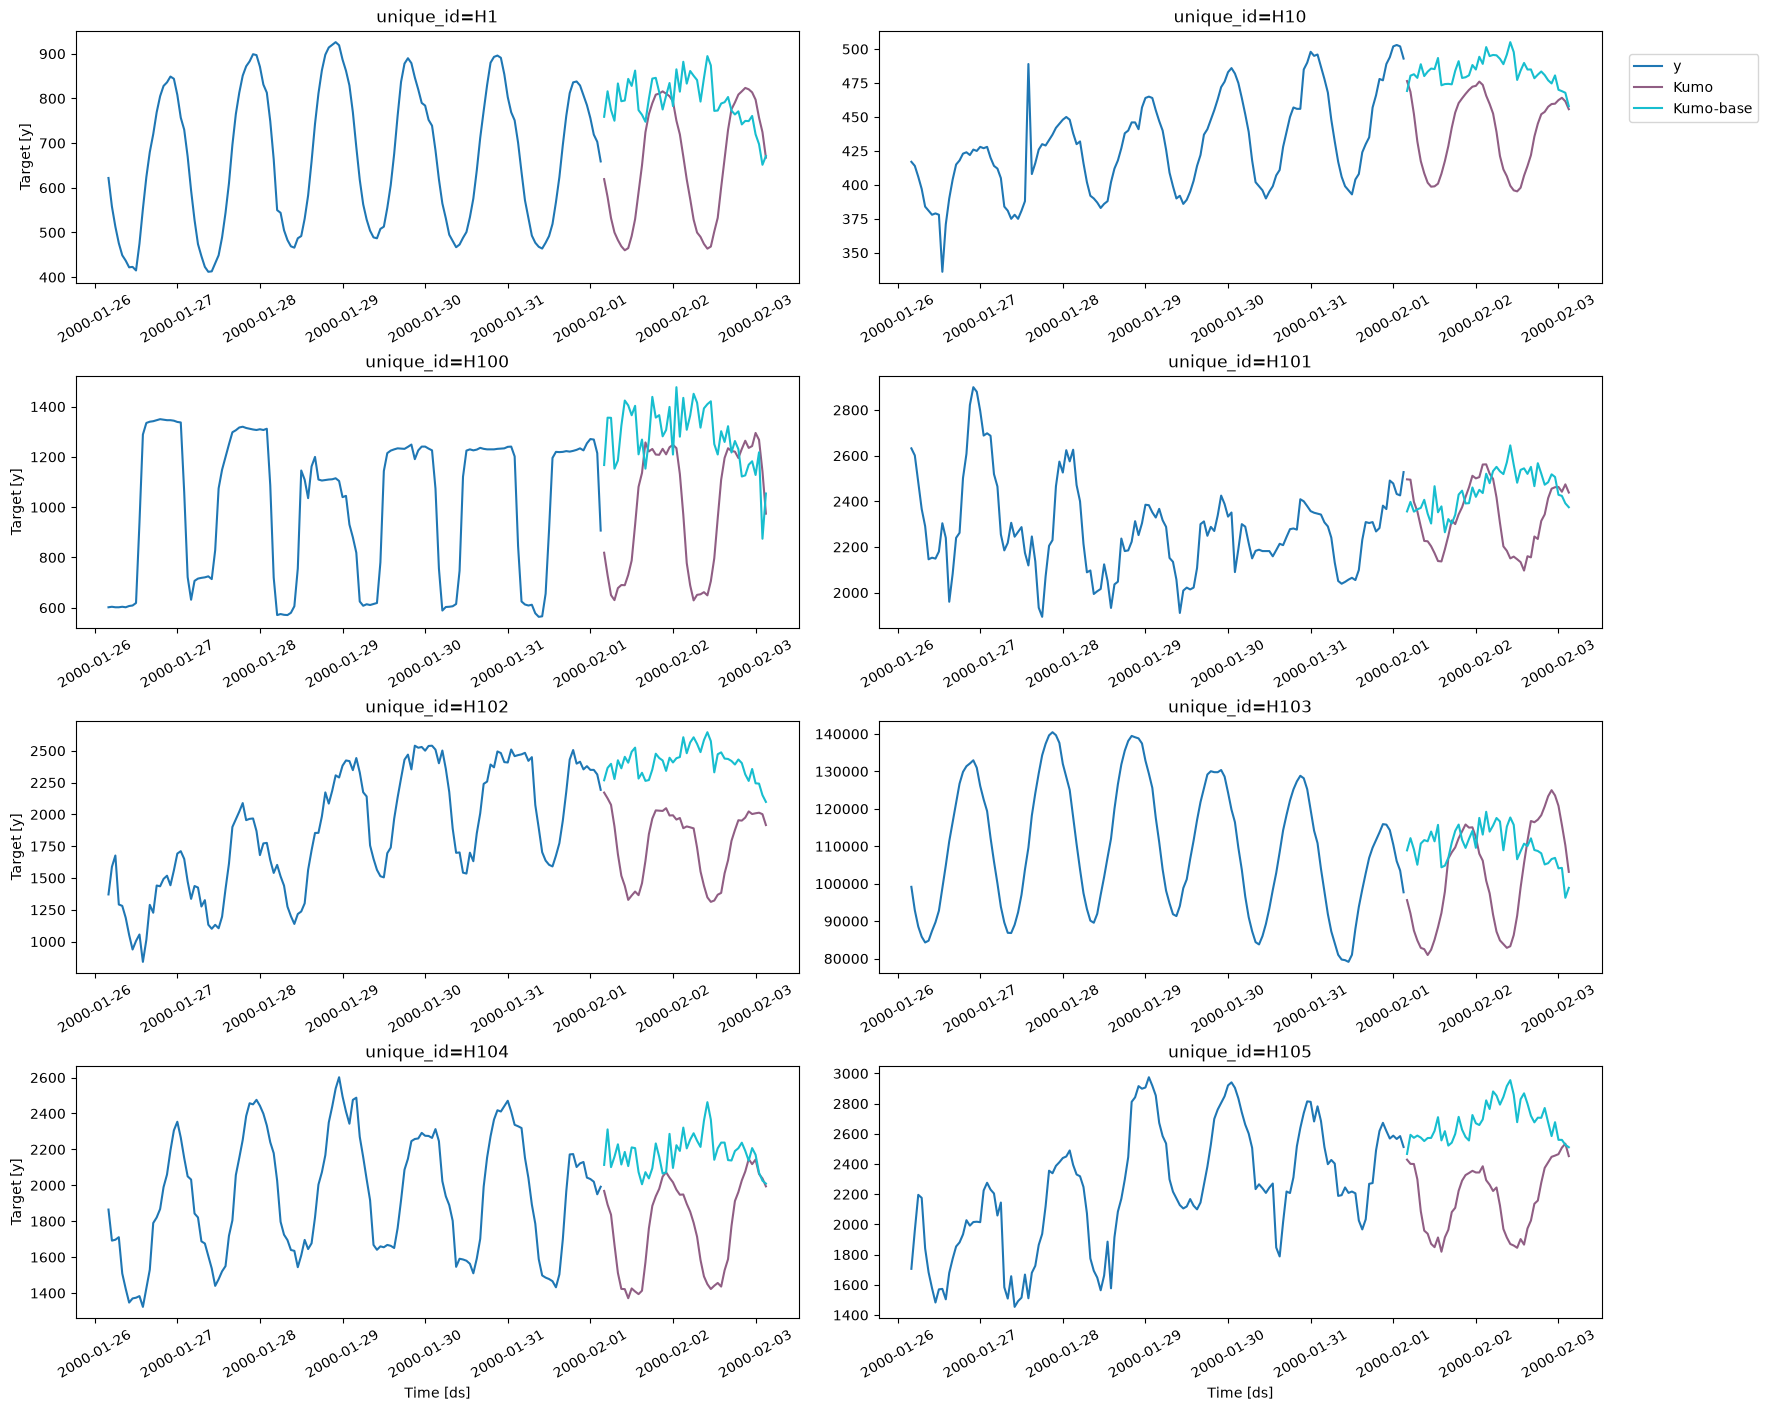

In [8]:
ff.plot(df, fcst_df, max_insample_length=48 * 3, plot_random=False)

## Prediction intervals

Since Kumo has no native quantiles, asking for `level` or `quantiles` raises an error instead of returning made-up intervals:

In [9]:
try:
    ff.forecast(df=df, h=h, level=[80])
except ValueError as err:
    print(err)

Kumo produces point forecasts only, so `level` and `quantiles` need conformal intervals: create the model with `prediction_intervals=ConformalIntervals(...)`.


Pass `prediction_intervals=ConformalIntervals(...)` to calibrate the intervals from the cross-validation errors of Kumo's own point forecast. See [Conformal prediction](conformal-prediction.ipynb) for the details.

In [10]:
prediction_intervals = ConformalIntervals(n_windows=10)

ff_conformal = FoundationForecast(
    models=[
        Kumo(alias="Kumo-CF", prediction_intervals=prediction_intervals),
        Kumo(
            checkpoint="moment_head_512_6hr.pt",
            alias="Kumo-base-CF",
            prediction_intervals=prediction_intervals,
        ),
    ]
)

level = [80, 95]
fcst_cf_df = ff_conformal.forecast(df=df, h=h, level=level)
fcst_cf_df.head()

,unique_id,ds,Kumo-CF,Kumo-CF-lo-95,Kumo-CF-lo-80,Kumo-CF-hi-80,Kumo-CF-hi-95,Kumo-base-CF,Kumo-base-CF-lo-95,Kumo-base-CF-lo-80,Kumo-base-CF-hi-80,Kumo-base-CF-hi-95
0,H1,2000-02-01 04:00:00,619.416809,567.620648,582.082135,656.751483,671.212970,758.959656,588.034503,601.630084,916.289227,929.884808
1,H1,2000-02-01 05:00:00,579.589050,500.423973,510.300989,648.877112,658.754128,816.005615,512.972974,532.293933,1099.717297,1119.038257
2,H1,2000-02-01 06:00:00,532.249451,442.370451,450.003894,614.495007,622.128450,774.137329,485.175992,504.874158,1043.400500,1063.098666
3,H1,2000-02-01 07:00:00,500.108124,383.297871,404.205151,596.011096,616.918376,750.082458,434.280257,441.146021,1059.018896,1065.884660
4,H1,2000-02-01 08:00:00,483.022736,377.349161,399.528021,566.517450,588.696310,833.545044,445.060863,461.824933,1205.265155,1222.029225


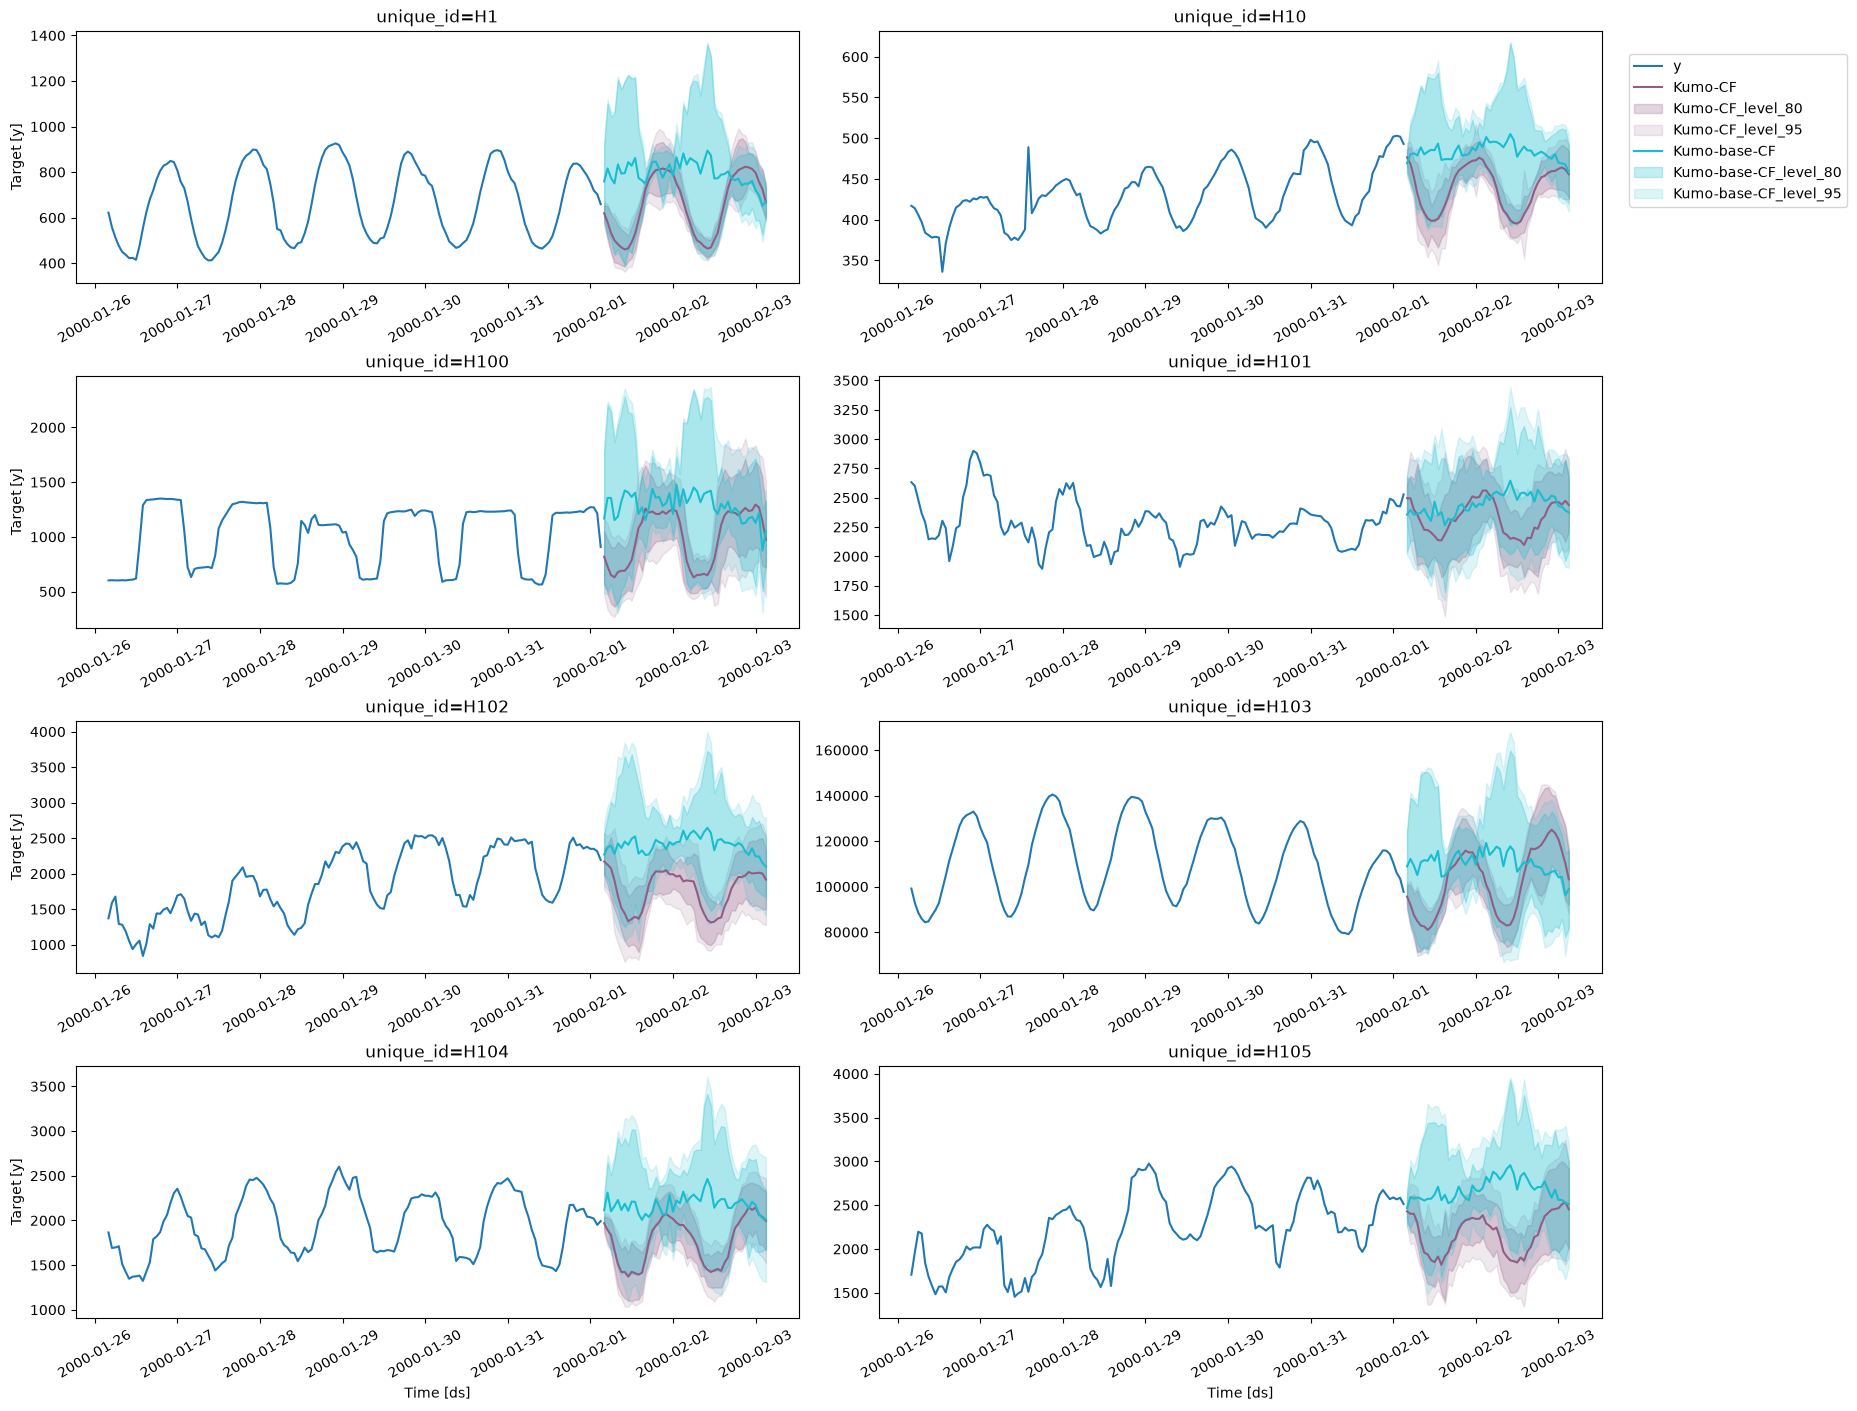

In [11]:
ff_conformal.plot(
    df,
    fcst_cf_df,
    models=["Kumo-CF", "Kumo-base-CF"],
    level=level,
    max_insample_length=48 * 3,
    plot_random=False,
)

## Cross validation

`cross_validation()` recalibrates the conformal intervals at every cutoff using only data before it.

In [12]:
cv_df = ff_conformal.cross_validation(df=df, h=h, n_windows=2, level=level)
cv_df.head()

,unique_id,ds,cutoff,y,Kumo-CF,Kumo-CF-lo-95,Kumo-CF-lo-80,Kumo-CF-hi-80,Kumo-CF-hi-95,Kumo-base-CF,Kumo-base-CF-lo-95,Kumo-base-CF-lo-80,Kumo-base-CF-hi-80,Kumo-base-CF-hi-95
0,H1,2000-01-28 04:00:00,2000-01-28 03:00:00,664.0,672.072571,587.410333,609.598889,734.546252,756.734808,760.006104,589.080951,611.267621,908.744586,930.931256
1,H1,2000-01-28 05:00:00,2000-01-28 03:00:00,550.0,616.049194,496.174544,531.703729,700.394659,735.923845,828.305603,528.357156,568.417126,1088.194080,1128.254050
2,H1,2000-01-28 06:00:00,2000-01-28 03:00:00,544.0,547.845154,396.197713,449.075629,646.614679,699.492595,788.010742,477.745148,483.713617,1092.307867,1098.276337
3,H1,2000-01-28 07:00:00,2000-01-28 03:00:00,505.0,506.039062,306.512369,365.893994,646.184131,705.565756,750.861572,401.931975,432.426630,1069.296515,1099.791170
4,H1,2000-01-28 08:00:00,2000-01-28 03:00:00,483.0,484.593384,321.601666,360.767651,608.419116,647.585101,849.670227,465.055365,484.486334,1214.854120,1234.285089


## Evaluation

In [13]:
from functools import partial

from utilsforecast.evaluation import evaluate
from utilsforecast.losses import coverage, mase, scaled_crps

In [14]:
eval_df = evaluate(
    cv_df.drop(columns=["cutoff"]),
    train_df=df,
    metrics=[partial(mase, seasonality=24), scaled_crps, coverage],
    level=level,
)
eval_df.groupby("metric").mean(numeric_only=True).T.round(3)

metric,coverage_level80,coverage_level95,mase,scaled_crps
Kumo-CF,0.865,0.941,0.883,0.027
Kumo-base-CF,0.785,0.913,2.528,0.043


**Reading the results:**
- Both conformal copies are close to the nominal 80% and 95% coverage on this hourly panel; the default checkpoint's intervals are tighter (lower scaled CRPS) because its point forecast is far more accurate.
- The default `run8_best_model_cr.pt` is much more accurate here (MASE 0.88 vs 2.53). The base checkpoint `moment_head_512_6hr.pt` is the one trained for a 6-hour standard forecasting setup, so treat the default as the starting point and compare on your own data before switching.